# UD02 · Notebook 1 — Lógica difusa: el problema de la propina

**Objetivo**: ver resueltas, de principio a fin, las tres fases de un sistema de inferencia
difuso (FIS, §7.4) — **fuzzificación**, **evaluación de reglas** y **desfuzzificación** — sobre
el ejemplo clásico de la propina (§7.6).

Es un notebook **guiado**: está ya resuelto y explicado. **No se entrega ni se puntúa** — ábrelo
para repasar el ejemplo antes de hacer `N02` (control difuso) y `N03` (sistema de reglas), o
antes de la prueba escrita del RA2.

## Antes de empezar

```bash
docker compose up -d            # si usas el contenedor del curso
pip install scikit-fuzzy==0.5.0
```

`scikit-fuzzy` es una librería **semi-mantenida** (última versión 2024): para que este notebook
reproduzca los resultados, fija la versión `0.5.0`.

## Fase 1 — Variables de entrada (fuzzificación)

El problema: la propina depende de la **calidad de la comida** (0-10) y del **servicio** (0-10).
Las dos se parten en 3 funciones de pertenencia triangulares con `automf(3, ...)`, que reparte el
universo en tres curvas solapadas con nombres propios — la forma más rápida de fuzzificar una
variable cuando no hace falta una forma a medida (compara con la lectura manual de §7.2).

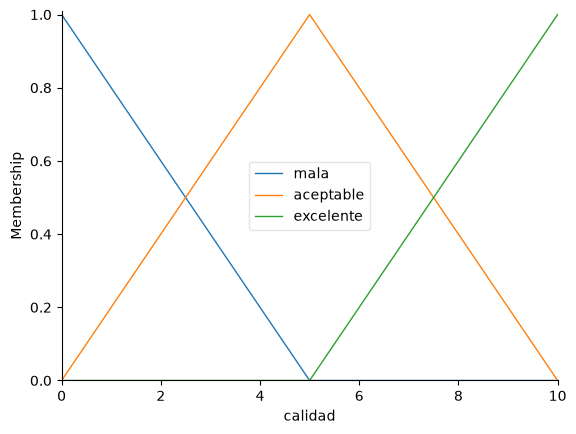

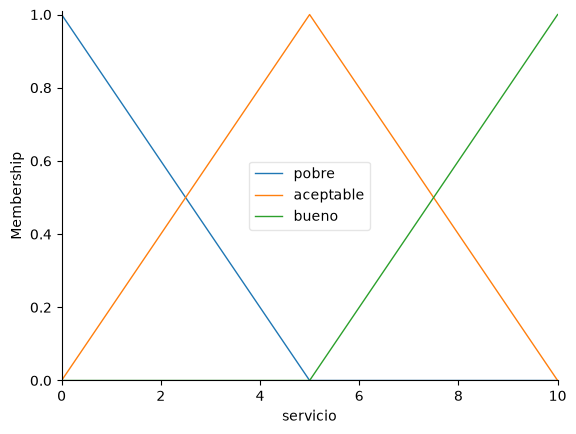

In [1]:
%pip install scikit-fuzzy

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Antecedentes: universo de discurso 0-10
calidad = ctrl.Antecedent(np.arange(0, 11, 1), 'calidad')
servicio = ctrl.Antecedent(np.arange(0, 11, 1), 'servicio')

# Consecuente: universo de discurso 0-25 (% de propina)
propina = ctrl.Consequent(np.arange(0, 26, 1), 'propina')

calidad.automf(3, names=['mala', 'aceptable', 'excelente'])
servicio.automf(3, names=['pobre', 'aceptable', 'bueno'])

calidad.view()
servicio.view()

Las dos figuras muestran tres curvas triangulares solapadas por variable: por ejemplo, una
calidad de 6 pertenece **a la vez** un poco a «aceptable» y un poco a «excelente», con distinto
grado. Esa es la fuzzificación: convertir un número nítido (*crisp*) en varios grados de
pertenencia µ(x) ∈ [0,1] (§7.1-§7.2).

## Fase 2 — Variable de salida y reglas

`propina` no usa `automf`: sus tres curvas se definen a mano con `trimf` para controlar los
puntos exactos de la teoría. Después, las tres reglas IF-THEN combinan las entradas con **OR**
(`|`, el máximo de los grados — §7.3):

1. calidad mala **o** servicio pobre → propina baja
2. servicio aceptable → propina media
3. servicio bueno **o** calidad excelente → propina alta

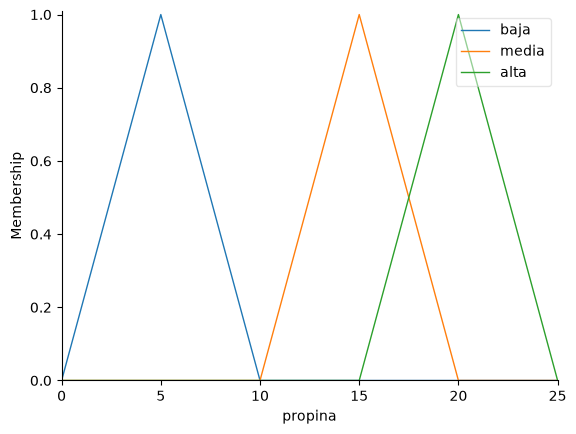

In [2]:
propina['baja'] = fuzz.trimf(propina.universe, [0, 5, 10])
propina['media'] = fuzz.trimf(propina.universe, [10, 15, 20])
propina['alta'] = fuzz.trimf(propina.universe, [15, 20, 25])

propina.view()

regla1 = ctrl.Rule(calidad['mala'] | servicio['pobre'], propina['baja'])
regla2 = ctrl.Rule(servicio['aceptable'], propina['media'])
regla3 = ctrl.Rule(servicio['bueno'] | calidad['excelente'], propina['alta'])

## Fase 3 — Inferencia y desfuzzificación

Con las reglas montadas en un `ControlSystem`, cada `ControlSystemSimulation` fuzzifica las
entradas, evalúa las tres reglas y **desfuzzifica** el resultado por centroide (centro de
gravedad del área resultante) para devolver un número nítido — el mismo caso de la teoría
(§7.6): calidad 6,5, servicio 9,8.

Propina sugerida: 19.70%


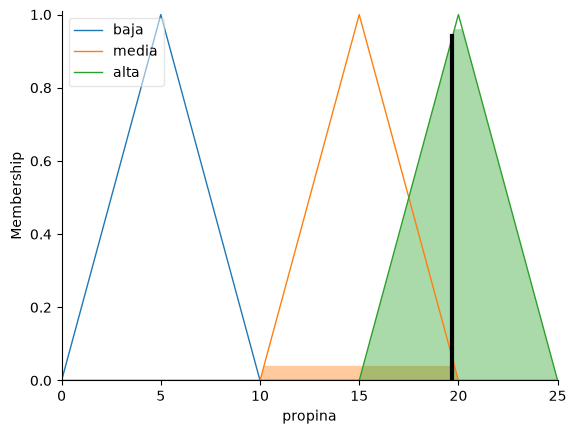

In [3]:
sistema = ctrl.ControlSystem([regla1, regla2, regla3])
sim = ctrl.ControlSystemSimulation(sistema)

sim.input['calidad'] = 6.5
sim.input['servicio'] = 9.8
sim.compute()

print(f"Propina sugerida: {sim.output['propina']:.2f}%")
propina.view(sim=sim)

La propina sale en torno al **20 %**, como en la teoría (el valor exacto depende de la resolución
del universo, `np.arange(0, 26, 1)`). En la figura, la línea vertical marca el centroide del área
difusa resultante: así se ve literalmente la fase de **desfuzzificación**, no solo su número.

## Fase 4 — Un segundo escenario, para contrastar

El mismo sistema, sin tocar ni una regla, con **calidad 3** y **servicio 2** (mal servicio y
comida floja): deberían dominar la regla 1 (propina baja).

Propina sugerida: 9.32%


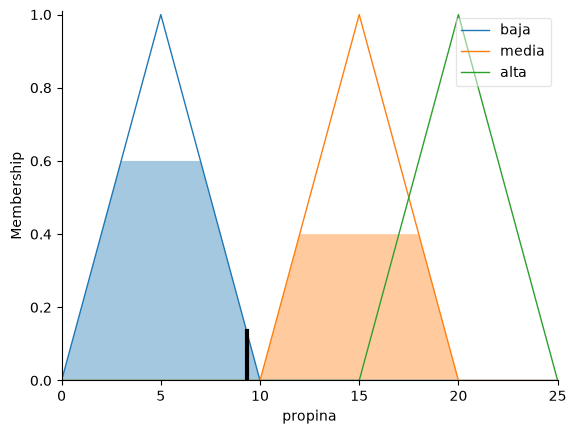

In [4]:
sim2 = ctrl.ControlSystemSimulation(sistema)
sim2.input['calidad'] = 3.0
sim2.input['servicio'] = 2.0
sim2.compute()

print(f"Propina sugerida: {sim2.output['propina']:.2f}%")
propina.view(sim=sim2)

La propina baja hasta en torno al **9 %**: con calidad 3 y servicio 2, «calidad mala» y «servicio
pobre» tienen un grado de pertenencia alto, así que la regla 1 domina la agregación y el centroide
se desplaza hacia el extremo «baja» del universo de `propina`. Cambia tú los dos valores de
entrada y vuelve a ejecutar esta celda para ver cómo se mueve el resultado — es la forma más
rápida de entender el FIS sin tener que leer el código de `scikit-fuzzy`.

## Resumen

| Fase | Qué se ha hecho | Dónde está en la teoría |
|---|---|---|
| 1 | Fuzzificar `calidad` y `servicio` con `automf` | §7.1-§7.2 |
| 2 | Definir `propina` a mano y las 3 reglas con OR (máximo) | §7.3 |
| 3 | Montar el `ControlSystem`, simular y desfuzzificar por centroide | §7.4, §7.6 |
| 4 | Repetir con otra entrada para ver el efecto en el resultado | — |

Las tres fases — fuzzificación, evaluación de reglas, desfuzzificación — son siempre las mismas,
cambie lo que cambie el problema: es lo que vas a volver a montar tú mismo, sin este guion, en el
notebook de entrega `N02` (control difuso de un ventilador).